In [16]:
import random, time
from dataclasses import dataclass, field
from pathlib import Path

import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

In [17]:
# CONFIGURACIÓN
CARPETA = r"./dataset_manzanas"
SUBCARPETA_IMAGENES = "imagenes"
SUBCARPETA_MASCARAS = "mascaras"
SEMILLA = 42
FRAC_AJUSTE = 0.7 # 70 % ajuste de parámetros / 30 % test final

In [18]:
# Lista de nombres de archivo (las máscaras se llaman igual que las imágenes)
nombres = sorted(os.listdir(os.path.join(CARPETA, SUBCARPETA_IMAGENES)))

# División ajuste / test, reproducible gracias a la semilla
random.seed(SEMILLA)
random.shuffle(nombres)
corte = int(len(nombres) * FRAC_AJUSTE)
ajuste = nombres[:corte]
test = nombres[corte:]

def cargar_par(nombre):
    """Devuelve la imagen (BGR) y su máscara binaria (0/1)."""
    img = cv.imread(os.path.join(CARPETA, SUBCARPETA_IMAGENES, nombre))
    mascara = cv.imread(os.path.join(CARPETA, SUBCARPETA_MASCARAS, nombre), cv.IMREAD_GRAYSCALE)
    return img, (mascara > 127).astype(np.uint8)

print(len(nombres), "imágenes |", len(ajuste), "ajuste |", len(test), "test")

100 imágenes | 70 ajuste | 30 test


In [19]:

# =========================
# MÉTRICAS (VERSIÓN OPTIMIZADA)
# =========================

def _div(a, b):
    return a / b if b > 0 else 0.0


def metricas_pixel(pred, gt):
    """Calcula las métricas de segmentación a nivel de píxel."""
    p = pred > 0
    g = gt > 0

    TP = int(np.sum(p & g))
    TN = int(np.sum(~p & ~g))
    FP = int(np.sum(p & ~g))
    FN = int(np.sum(~p & g))

    return {
        "TP": TP,
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "exactitud": _div(TP + TN, p.size),
        "precision": _div(TP, TP + FP),
        "recall": _div(TP, TP + FN),
        "iou": _div(TP, TP + FP + FN),
        "dice": _div(2 * TP, 2 * TP + FP + FN)
    }


def _componentes_validos(binary, area_min=30):
    """
    Detecta componentes conectados y conserva únicamente
    aquellos cuya área sea igual o superior a area_min.
    """
    binary = (binary > 0).astype(np.uint8)

    n, labels, stats, _ = cv.connectedComponentsWithStats(
        binary, connectivity=8
    )

    areas = stats[:, cv.CC_STAT_AREA]
    ids_validos = np.where(areas >= area_min)[0]
    ids_validos = ids_validos[ids_validos != 0]  # Excluir fondo

    return labels, ids_validos, areas


def _best_iou_matching(pred, gt, iou_min=0.5, area_min=30):
    """
    Emparejamiento 1 a 1 entre objetos predichos y reales.
    Utiliza el IoU real y evita crear máscaras individuales
    para cada componente.
    """

    lp, ids_p, areas_p = _componentes_validos(pred, area_min)
    lg, ids_g, areas_g = _componentes_validos(gt, area_min)

    n_pred = len(ids_p)
    n_gt = len(ids_g)

    # Caso en el que no hay objetos en alguna de las imágenes
    if n_pred == 0 or n_gt == 0:
        TP = 0

    else:
        # Crear mapas de etiquetas compactos
        mapa_p = np.zeros(int(lp.max()) + 1, dtype=np.int32)
        mapa_g = np.zeros(int(lg.max()) + 1, dtype=np.int32)

        mapa_p[ids_p] = np.arange(1, n_pred + 1)
        mapa_g[ids_g] = np.arange(1, n_gt + 1)

        p = mapa_p[lp]
        g = mapa_g[lg]

        # Calcular intersecciones entre todos los pares
        validos = (p > 0) & (g > 0)

        codigos = p[validos] * (n_gt + 1) + g[validos]

        intersecciones = np.bincount(
            codigos,
            minlength=(n_pred + 1) * (n_gt + 1)
        ).reshape(n_pred + 1, n_gt + 1)

        intersecciones = intersecciones[1:, 1:]

        # Calcular IoU de cada pareja
        areas_pred = areas_p[ids_p]
        areas_gt = areas_g[ids_g]

        uniones = (
            areas_pred[:, None]
            + areas_gt[None, :]
            - intersecciones
        )

        ious = np.divide(
            intersecciones,
            uniones,
            out=np.zeros_like(intersecciones, dtype=float),
            where=uniones > 0
        )

        # Seleccionar parejas que superan el IoU mínimo
        pares = np.argwhere(ious >= iou_min)

        # Priorizar las parejas con mayor IoU
        pares = sorted(
            pares,
            key=lambda par: ious[par[0], par[1]],
            reverse=True
        )

        # Emparejamiento 1 a 1
        usados_p = set()
        usados_g = set()
        TP = 0

        for i, j in pares:
            if i not in usados_p and j not in usados_g:
                usados_p.add(i)
                usados_g.add(j)
                TP += 1

    # Calcular falsos positivos y negativos
    FP = n_pred - TP
    FN = n_gt - TP

    precision = _div(TP, TP + FP)
    recall = _div(TP, TP + FN)
    f1 = _div(2 * precision * recall, precision + recall)

    return {
        "obj_TP": TP,
        "obj_FP": FP,
        "obj_FN": FN,
        "obj_precision": precision,
        "obj_recall": recall,
        "obj_f1": f1,
        "n_gt": n_gt,
        "n_pred": n_pred,
        "error_conteo": n_pred - n_gt
    }


def metricas_objeto(pred, gt, iou_min=0.5, area_min=30):
    """Calcula las métricas de objetos mediante IoU real."""
    return _best_iou_matching(
        pred,
        gt,
        iou_min=iou_min,
        area_min=area_min
    )


def metricas_completas(pred, gt):
    """Combina las métricas de píxel y de objeto."""
    fila = metricas_pixel(pred, gt)
    fila.update(metricas_objeto(pred, gt))
    fila["error_abs"] = abs(fila["error_conteo"])

    return fila


In [20]:
# ---------- Preprocesado: reciben una imagen y devuelven una imagen ----------
def mediana(img, k=5):
    return cv.medianBlur(img, k)                  # k debe ser impar

def gauss(img, k=5, sigma=1.5):
    return cv.GaussianBlur(img, (k, k), sigma)    # k debe ser impar

def clahe_l(img, clip=2.0, tile=8):
    """CLAHE sobre la luminosidad (canal L de Lab): corrige luz desigual."""
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    clahe = cv.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile))
    lab[:, :, 0] = clahe.apply(lab[:, :, 0])
    return cv.cvtColor(lab, cv.COLOR_LAB2BGR)

# ---------- Segmentación: recibe una imagen y devuelve una máscara ----------
def umbral_hsv(img, h=(22, 40), s=(70, 255), v=(90, 255)):
    """Método base: rango de color en HSV (valores de partida, SIN ajustar)."""
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    return cv.inRange(hsv, (h[0], s[0], v[0]), (h[1], s[1], v[1]))

# ---------- Postprocesado: reciben máscara (y la imagen) y devuelven máscara ----------
def abrir_cerrar(mascara, img, k_abrir=3, k_cerrar=5):
    m = (mascara > 0).astype(np.uint8) * 255
    k1 = cv.getStructuringElement(cv.MORPH_ELLIPSE, (k_abrir, k_abrir))
    k2 = cv.getStructuringElement(cv.MORPH_ELLIPSE, (k_cerrar, k_cerrar))
    m = cv.morphologyEx(m, cv.MORPH_OPEN, k1)      # quita motas pequeñas
    m = cv.morphologyEx(m, cv.MORPH_CLOSE, k2)     # rellena huecos
    return m

def filtrar_area(mascara, img, area_min=40, area_max=None):
    m = (mascara > 0).astype(np.uint8)
    n, etiquetas, stats, _ = cv.connectedComponentsWithStats(m, connectivity=8)
    salida = np.zeros_like(m)
    for i in range(1, n):                          # la etiqueta 0 es el fondo
        area = stats[i, cv.CC_STAT_AREA]
        if area >= area_min and (area_max is None or area <= area_max):
            salida[etiquetas == i] = 255
    return salida

# Diccionario para llamar a cada función por su nombre
CATALOGO = {"mediana": mediana, "gauss": gauss, "clahe_l": clahe_l,
            "umbral_hsv": umbral_hsv,
            "abrir_cerrar": abrir_cerrar, "filtrar_area": filtrar_area}

class Metodo:
    """Un método = preprocesados -> segmentador -> postprocesados.
    Cada etapa se escribe como (nombre, {parámetros}). Se usa como una función: metodo(img) -> máscara."""
    def __init__(self, nombre, seg, preproc=None, post=None):
        self.nombre = nombre
        self.seg = seg
        self.preproc = preproc or []
        self.post = post or []

    def __call__(self, img):
        x = img
        for nombre, params in self.preproc:
            x = CATALOGO[nombre](x, **params)
        nombre, params = self.seg
        mascara = CATALOGO[nombre](x, **params)
        for nombre, params in self.post:
            mascara = CATALOGO[nombre](mascara, img, **params)
        return (mascara > 0).astype(np.uint8)

print("Componentes disponibles:", list(CATALOGO))

Componentes disponibles: ['mediana', 'gauss', 'clahe_l', 'umbral_hsv', 'abrir_cerrar', 'filtrar_area']


In [21]:
def evaluar(metodo, nombres):
    filas = []
    for nombre in nombres:
        img, gt = cargar_par(nombre)
        pred = metodo(img)
        fila = {"metodo": metodo.nombre, "id": nombre}
        fila.update(metricas_completas(pred, gt))
        filas.append(fila)
    return pd.DataFrame(filas)

def comparar(metodos, nombres):
    tablas = [evaluar(m, nombres) for m in metodos]
    return pd.concat(tablas, ignore_index=True)

def resumen(tabla):
    columnas = [
        "iou", "dice", "precision", "recall",
        "obj_f1", "obj_precision", "obj_recall",
        "error_conteo", "error_abs"
    ]
    return tabla.groupby("metodo")[columnas].mean().sort_values(
        ["dice", "obj_f1"], ascending=False
    )

def mostrar(img, pred, gt, titulo=""):
    errores = np.zeros((*gt.shape, 3), dtype=np.uint8)
    errores[(pred > 0) & (gt > 0)] = (0, 255, 0)
    errores[(pred > 0) & (gt == 0)] = (255, 0, 0)
    errores[(pred == 0) & (gt > 0)] = (0, 0, 255)

    fig, ax = plt.subplots(1, 4, figsize=(17, 6))
    ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax[0].set_title("Original")
    ax[1].imshow(gt, cmap="gray")
    ax[1].set_title("Máscara real")
    ax[2].imshow(pred, cmap="gray")
    ax[2].set_title("Predicción")
    ax[3].imshow(errores)
    ax[3].set_title("Verde=acierto | Rojo=FP | Azul=FN")
    for a in ax:
        a.axis("off")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


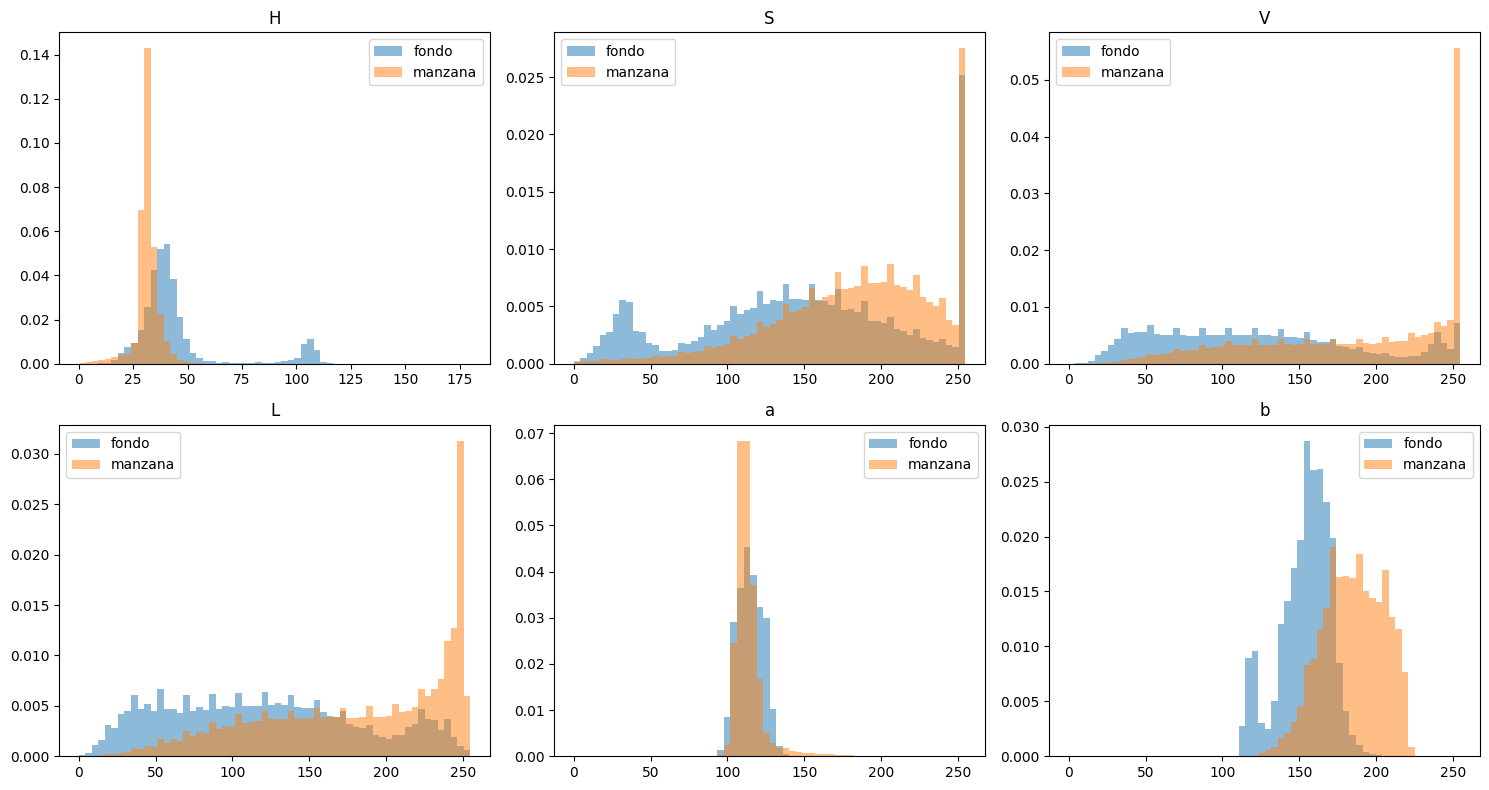

H: manzana   31.1 ±   7.2 | fondo   44.7 ±  21.9
S: manzana  183.5 ±  52.7 | fondo  146.8 ±  68.3
V: manzana  185.3 ±  64.6 | fondo  122.5 ±  64.6
L: manzana  180.3 ±  61.5 | fondo  120.2 ±  63.0
a: manzana  113.5 ±   9.4 | fondo  114.8 ±   8.2
b: manzana  184.8 ±  19.9 | fondo  153.8 ±  16.7


In [22]:
manzana = []   # cada fila: [H, S, V, L, a, b] de un píxel de manzana
fondo = []     # lo mismo para píxeles de fondo

for nombre in ajuste:
    img, gt = cargar_par(nombre)
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    pixeles = np.dstack([hsv, lab]).reshape(-1, 6)
    etiqueta = gt.reshape(-1)
    manzana.append(pixeles[etiqueta == 1][::5])    # 1 de cada 5 píxeles
    fondo.append(pixeles[etiqueta == 0][::50])     # 1 de cada 50 (hay muchos más)

manzana = np.vstack(manzana)
fondo = np.vstack(fondo)

canales = ["H", "S", "V", "L", "a", "b"]

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax = ax.flatten()
for i, c in enumerate(canales):
    rango = (0, 180) if c == "H" else (0, 255)    # en OpenCV, H va de 0 a 180
    ax[i].hist(fondo[:, i], bins=60, range=rango, density=True, alpha=0.5, label="fondo")
    ax[i].hist(manzana[:, i], bins=60, range=rango, density=True, alpha=0.5, label="manzana")
    ax[i].set_title(c)
    ax[i].legend()
plt.tight_layout()
plt.show()

for i, c in enumerate(canales):
    print(f"{c}: manzana {manzana[:, i].mean():6.1f} ± {manzana[:, i].std():5.1f} | "
          f"fondo {fondo[:, i].mean():6.1f} ± {fondo[:, i].std():5.1f}")

In [23]:
# Cada píxel de manzana muestreado representa 5 reales, y cada píxel de fondo, 50
peso_manzana = 5
peso_fondo = 50

for i, c in enumerate(canales):
    # Cuántos píxeles hay con cada valor (0-255), ya ponderados
    hist_m = np.bincount(manzana[:, i], minlength=256) * peso_manzana
    hist_f = np.bincount(fondo[:, i], minlength=256) * peso_fondo
    # Sumas acumuladas: permiten contar píxeles en un rango [lo, hi] de golpe
    acum_m = np.concatenate([[0], np.cumsum(hist_m)])
    acum_f = np.concatenate([[0], np.cumsum(hist_f)])
    total_m = acum_m[-1]

    mejor_dice, mejor_rango = 0, None
    for lo in range(256):
        for hi in range(lo, 256):
            TP = acum_m[hi + 1] - acum_m[lo]      # manzana dentro del rango
            FP = acum_f[hi + 1] - acum_f[lo]      # fondo dentro del rango
            FN = total_m - TP                     # manzana fuera del rango
            dice = 2 * TP / (2 * TP + FP + FN)
            if dice > mejor_dice:
                mejor_dice, mejor_rango = dice, (lo, hi)

    print(f"{c}: mejor rango {mejor_rango}  ->  Dice = {mejor_dice:.3f}")

H: mejor rango (29, 31)  ->  Dice = 0.326
S: mejor rango (192, 254)  ->  Dice = 0.156
V: mejor rango (248, 255)  ->  Dice = 0.253
L: mejor rango (241, 253)  ->  Dice = 0.287
a: mejor rango (107, 112)  ->  Dice = 0.133
b: mejor rango (185, 223)  ->  Dice = 0.581


In [24]:
def umbral_b(img, lo=185, hi=255):
    """Umbral sobre el canal b de Lab (azul↔amarillo): las manzanas son amarillo-verdosas."""
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    return cv.inRange(lab[:, :, 2], lo, hi)

CATALOGO["umbral_b"] = umbral_b      # lo añadimos al diccionario de componentes

m_base = Metodo("HSV base", seg=("umbral_hsv", {}))
m_b = Metodo("b solo", seg=("umbral_b", {}))
m_b_med = Metodo("b + mediana", preproc=[("mediana", {"k": 5})], seg=("umbral_b", {}))
m_b_post = Metodo("b + mediana + morfología",
                  preproc=[("mediana", {"k": 5})],
                  seg=("umbral_b", {}),
                  post=[("abrir_cerrar", {}), ("filtrar_area", {"area_min": 40})])

tabla = comparar([m_base, m_b, m_b_med, m_b_post], ajuste)
print(resumen(tabla).round(3).to_string())

                            iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                               
b + mediana + morfología  0.350  0.475      0.585   0.423   0.257          0.234       0.291        29.757     31.071
b + mediana               0.345  0.471      0.570   0.426   0.241          0.208       0.294        44.686     45.286
b solo                    0.337  0.463      0.570   0.413   0.224          0.188       0.282        52.871     53.386
HSV base                  0.098  0.172      0.101   0.660   0.022          0.015       0.045       147.100    147.100


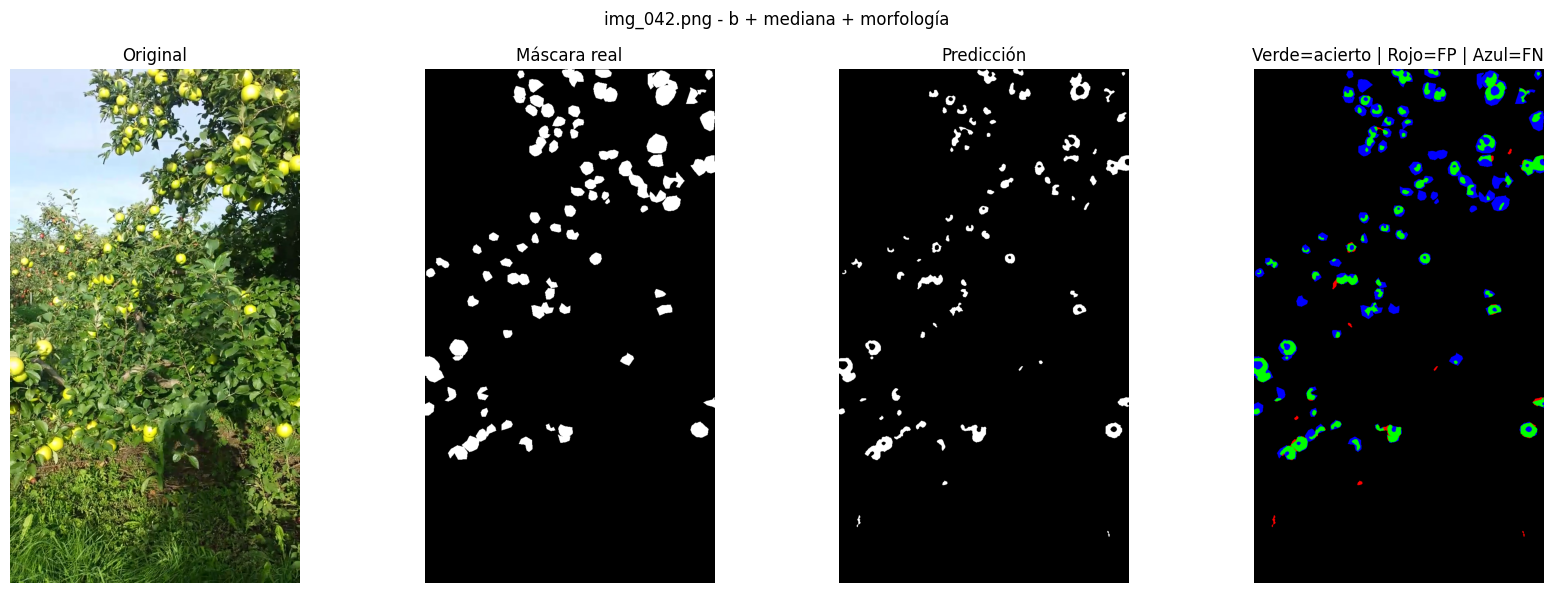

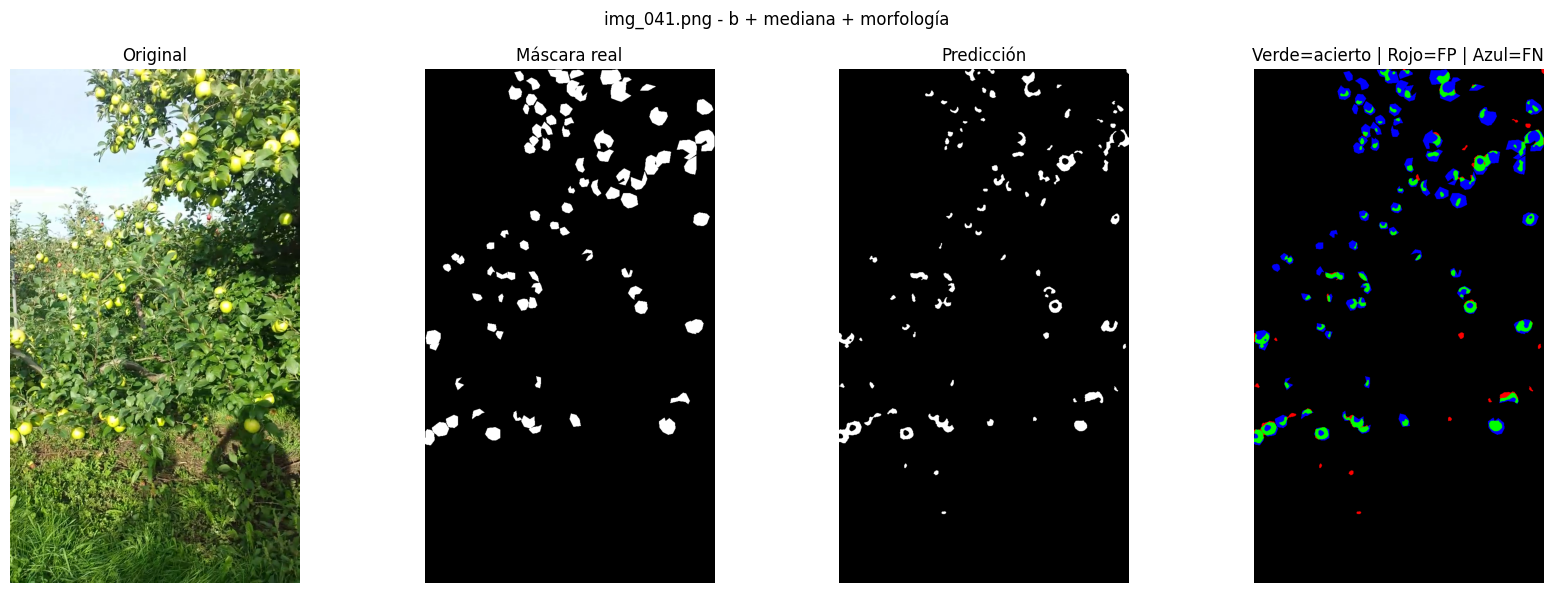

In [25]:
for nombre in ajuste[:2]:
    img, gt = cargar_par(nombre)
    pred = m_b_post(img)
    mostrar(img, pred, gt, nombre + " - b + mediana + morfología")

In [26]:
def rellenar_huecos(mascara, img):
    """Rellena los huecos interiores de cada mancha (p. ej. el brillo en el centro de una manzana)."""
    m = (mascara > 0).astype(np.uint8)
    contornos, _ = cv.findContours(m, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    salida = np.zeros_like(m)
    cv.drawContours(salida, contornos, -1, 255, cv.FILLED)
    return salida

CATALOGO["rellenar_huecos"] = rellenar_huecos

post_basico = [("abrir_cerrar", {}), ("rellenar_huecos", {}), ("filtrar_area", {"area_min": 40})]

metodos = [m_b_post]    # referencia: b=185 sin rellenar huecos
for lo in [185, 175, 165, 155]:
    metodos.append(Metodo(f"b>={lo} + relleno",
                          preproc=[("mediana", {"k": 5})],
                          seg=("umbral_b", {"lo": lo}),
                          post=post_basico))

tabla = comparar(metodos, ajuste[:20])    # 20 imágenes para ir rápido
print(resumen(tabla).round(3).to_string())

                            iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                               
b>=185 + relleno          0.350  0.468      0.590   0.416   0.255          0.240       0.276         27.80      31.60
b + mediana + morfología  0.336  0.455      0.586   0.400   0.249          0.234       0.269         27.80      31.60
b>=175 + relleno          0.274  0.398      0.324   0.620   0.164          0.116       0.326        138.90     138.90
b>=165 + relleno          0.117  0.201      0.119   0.837   0.076          0.057       0.122         89.25      89.25
b>=155 + relleno          0.066  0.121      0.066   0.975   0.041          0.049       0.036        -12.60      23.70


In [27]:
def adaptativo_b(img, bloque=51, c=10, minimo=150):
    """Umbral LOCAL sobre b: el píxel debe superar en 'c' la media de su entorno (bloque x bloque).
    'minimo' evita que zonas oscuras o grises (con b bajo) cuenten como manzana."""
    b = cv.cvtColor(img, cv.COLOR_BGR2LAB)[:, :, 2]
    local = cv.adaptiveThreshold(b, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, bloque, -c)
    return ((local > 0) & (b >= minimo)).astype(np.uint8) * 255

CATALOGO["adaptativo_b"] = adaptativo_b

post_basico = [("abrir_cerrar", {}), ("rellenar_huecos", {}), ("filtrar_area", {"area_min": 40})]

# Referencia: el mejor método global hasta ahora
metodos = [Metodo("b>=185 global", preproc=[("mediana", {"k": 5})],
                  seg=("umbral_b", {"lo": 185}), post=post_basico)]

for bloque in [51, 151]:
    for c in [10, 20]:
        metodos.append(Metodo(f"adaptativo bloque={bloque} c={c}",
                              preproc=[("mediana", {"k": 5})],
                              seg=("adaptativo_b", {"bloque": bloque, "c": c}),
                              post=post_basico))

tabla = comparar(metodos, ajuste[:20])
print(resumen(tabla).round(3).to_string())

                              iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                                 
b>=185 global               0.350  0.468      0.590   0.416   0.255          0.240       0.276         27.80      31.60
adaptativo bloque=151 c=20  0.321  0.440      0.556   0.379   0.228          0.186       0.300         48.85      49.65
adaptativo bloque=51 c=10   0.259  0.380      0.436   0.362   0.133          0.089       0.277        163.25     163.25
adaptativo bloque=151 c=10  0.249  0.371      0.291   0.579   0.157          0.100       0.403        239.55     239.55
adaptativo bloque=51 c=20   0.122  0.204      0.608   0.125   0.047          0.046       0.049          3.55      12.95


- El adaptativo no supera al global. El mejor adaptativo (bloque 151, c=20) queda en Dice 0,440 frente a 0,468 del global, y con peor error de conteo (49,7 frente a 31,6). Es un resultado válido para la memoria: un umbral local no ayuda aquí. Probablemente porque en estas imágenes las manzanas están rodeadas de hojas con colores muy variables, y la media local no es un buen punto de comparación.
- Cuidado con bloque=51, c=20. Su error_conteo es solo 3,55 y su precisión 0,608, la más alta de la tabla. Pero el recall es 0,125 y el obj_f1 0,098: detecta muy pocas manzanas, y por eso comete pocos errores de conteo. Es la misma trampa de antes: un número bueno aislado que oculta un método que apenas funciona.
- Conclusión parcial: con un único canal de color (global o local) parece haber un techo en torno a Dice ≈ 0,47. Para pasar de ahí hay que usar más información. El siguiente paso lógico es combinar b con el brillo, porque en las gráficas las manzanas eran más claras que las hojas (L ≈ 180 frente a 120), y eso puede permitir bajar el umbral de b sin dejar pasar las hojas oscuras.

In [28]:
peso_m, peso_f = 5, 50       # cada píxel muestreado de manzana vale 5 reales; de fondo, 50
resultados = []
for b_lo in range(150, 201, 5):
    for L_lo in range(100, 251, 10):
        dentro_m = (manzana[:, 5] >= b_lo) & (manzana[:, 3] >= L_lo)    # columna 5 = b, columna 3 = L
        dentro_f = (fondo[:, 5] >= b_lo) & (fondo[:, 3] >= L_lo)
        TP = dentro_m.sum() * peso_m
        FP = dentro_f.sum() * peso_f
        FN = (len(manzana) - dentro_m.sum()) * peso_m
        resultados.append((2 * TP / (2 * TP + FP + FN), b_lo, L_lo))

resultados.sort(reverse=True)
print("Mejores combinaciones (Dice por píxel, con muestras):")
for dice, b_lo, L_lo in resultados[:5]:
    print(f"  b >= {b_lo}, L >= {L_lo}  ->  Dice = {dice:.3f}")

# --- Evaluar la mejor combinación como método real ---
def umbral_bL(img, b_lo=185, L_lo=0):
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    return ((lab[:, :, 2] >= b_lo) & (lab[:, :, 0] >= L_lo)).astype(np.uint8) * 255

CATALOGO["umbral_bL"] = umbral_bL

_, b_mejor, L_mejor = resultados[0]
post_basico = [("abrir_cerrar", {}), ("rellenar_huecos", {}), ("filtrar_area", {"area_min": 40})]

metodos = [Metodo("b>=185 global", preproc=[("mediana", {"k": 5})],
                  seg=("umbral_b", {"lo": 185}), post=post_basico),
           Metodo(f"b>={b_mejor} + L>={L_mejor}", preproc=[("mediana", {"k": 5})],
                  seg=("umbral_bL", {"b_lo": b_mejor, "L_lo": L_mejor}), post=post_basico)]

tabla = comparar(metodos, ajuste[:20])
print(resumen(tabla).round(3).to_string())

Mejores combinaciones (Dice por píxel, con muestras):
  b >= 185, L >= 120  ->  Dice = 0.581
  b >= 185, L >= 110  ->  Dice = 0.581
  b >= 185, L >= 100  ->  Dice = 0.581
  b >= 185, L >= 130  ->  Dice = 0.581
  b >= 185, L >= 140  ->  Dice = 0.578
                  iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                     
b>=185 + L>=120  0.35  0.468       0.59   0.416   0.255           0.24       0.276          27.8       31.6
b>=185 global    0.35  0.468       0.59   0.416   0.255           0.24       0.276          27.8       31.6


- El brillo no aporta nada. Las cinco mejores combinaciones tienen el mismo Dice (0,581) que b solo, y la tabla real da exactamente los mismos números que “b>=185 global”. Casi cualquier píxel con b ≥ 185 ya es claro (L > 100), así que el filtro de L no descarta nada que importe. La hipótesis era razonable y salió negativa, y eso también sirve para la memoria.
- Un umbral de color tiene un techo. Ya probamos b solo, el cambio de umbral, el umbral local y b+L. Todos acaban en Dice ≈ 0,47 sobre imágenes reales. Todos tienen algo en común: trazan una frontera “recta” en el espacio de color, y las hojas amarillentas y las manzanas en sombra se solapan en color.
- Qué probar ahora: un modelo de mezcla gaussiana (GMM), que está en la teoría. Un GMM agrupa los píxeles en varias “nubes” de color con forma y orientación propias (no solo rectángulos), y se ajusta a cada imagen por separado, así que se adapta a la luz de cada foto. Es el primer método del grupo de clustering que anoté.

In [29]:
from sklearn.mixture import GaussianMixture    # si falla: pip install scikit-learn

def gmm_color(img, k=4, muestra=20000):
    """Ajusta un GMM de k componentes al color (L,a,b) de ESTA imagen.
    La componente con mayor b medio (la más amarilla) se toma como manzana."""
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB).reshape(-1, 3).astype(np.float32)
    azar = np.random.RandomState(0)
    submuestra = lab[azar.choice(len(lab), muestra, replace=False)]   # ajustar con todos los píxeles sería lento
    gmm = GaussianMixture(n_components=k, random_state=0).fit(submuestra)
    componente_manzana = np.argmax(gmm.means_[:, 2])                  # columna 2 = b
    etiquetas = gmm.predict(lab)
    return (etiquetas == componente_manzana).reshape(img.shape[:2]).astype(np.uint8) * 255

CATALOGO["gmm_color"] = gmm_color

post_basico = [("abrir_cerrar", {}), ("rellenar_huecos", {}), ("filtrar_area", {"area_min": 40})]

metodos = [Metodo("b>=185 global", preproc=[("mediana", {"k": 5})],
                  seg=("umbral_b", {"lo": 185}), post=post_basico)]
for k in [3, 4, 6]:
    metodos.append(Metodo(f"GMM k={k}", preproc=[("mediana", {"k": 5})],
                          seg=("gmm_color", {"k": k}), post=post_basico))

tabla = comparar(metodos, ajuste[:10])     # 10 imágenes: el GMM es más lento
print(resumen(tabla).round(3).to_string())

c:\Users\pausa\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\pausa\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\pausa\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\pausa\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, c

                 iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                    
b>=185 global  0.363  0.485      0.602   0.433   0.260          0.251       0.272          27.0       29.4
GMM k=6        0.294  0.396      0.495   0.357   0.235          0.245       0.234          90.9      101.3
GMM k=4        0.093  0.157      0.103   0.563   0.060          0.043       0.100          82.3       82.3
GMM k=3        0.072  0.131      0.074   0.846   0.017          0.014       0.026          39.6       50.6


Ningún GMM supera al umbral de b. La referencia saca Dice 0,485 en estas 10 imágenes, y el mejor GMM (k=6) 0,396, con peor error de conteo (101 frente a 29).
El patrón confirma lo que sospechábamos. Con k=3 y k=4 la componente “más amarilla” absorbe también hojas claras: recall alto (0,85) y precisión muy baja (0,07-0,10). Con k=6 el modelo separa mejor, pero se queda corto.
Conclusión para la memoria: clustering de color por imagen no mejora al umbral de b. Manzanas y hojas amarillentas se solapan en color, y cambiar el algoritmo no resuelve eso. Lo dejamos como resultado negativo (con la salvedad de que probé una regla simple para elegir la componente de la manzana, no todas las variantes posibles).

In [30]:
def dilatar(mascara, img, k=5):
    kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (k, k))
    return cv.dilate((mascara > 0).astype(np.uint8) * 255, kernel)

def histeresis_b(img, alto=185, bajo=175):
    """Semillas: b >= alto. Se añaden los píxeles con b >= bajo conectados a una semilla."""
    b = cv.cvtColor(img, cv.COLOR_BGR2LAB)[:, :, 2]
    fuerte = b >= alto
    debil = (b >= bajo).astype(np.uint8)
    n, etiquetas = cv.connectedComponents(debil, connectivity=8)
    con_semilla = np.unique(etiquetas[fuerte])           # regiones débiles que contienen una semilla
    con_semilla = con_semilla[con_semilla > 0]
    return np.isin(etiquetas, con_semilla).astype(np.uint8) * 255

CATALOGO["dilatar"] = dilatar
CATALOGO["histeresis_b"] = histeresis_b

post_basico = [("abrir_cerrar", {}), ("rellenar_huecos", {}), ("filtrar_area", {"area_min": 40})]
pre = [("mediana", {"k": 5})]

metodos = [Metodo("b>=185 global", preproc=pre, seg=("umbral_b", {"lo": 185}), post=post_basico)]

# 1) Dilatar el resultado
for k in [5, 9]:
    metodos.append(Metodo(f"b>=185 + dilatar {k}", preproc=pre, seg=("umbral_b", {"lo": 185}),
                          post=post_basico + [("dilatar", {"k": k})]))

# 2) Crecimiento desde semillas (histéresis)
for bajo in [180, 175]:
    metodos.append(Metodo(f"histéresis 185/{bajo}", preproc=pre,
                          seg=("histeresis_b", {"alto": 185, "bajo": bajo}), post=post_basico))

tabla = comparar(metodos, ajuste[:20])
print(resumen(tabla).round(3).to_string())

                      iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                         
b>=185 + dilatar 5  0.379  0.497      0.516   0.524   0.334          0.317       0.363         25.35      29.75
b>=185 + dilatar 9  0.363  0.484      0.440   0.599   0.314          0.309       0.334         16.40      23.50
histéresis 185/180  0.352  0.473      0.497   0.505   0.252          0.217       0.316         49.15      50.45
b>=185 global       0.350  0.468      0.590   0.416   0.255          0.240       0.276         27.80      31.60
histéresis 185/175  0.310  0.436      0.381   0.603   0.245          0.215       0.324         39.00      40.10


Dilatar es lo mejor hasta ahora. Con k=5 el Dice sube de 0,468 a 0,497 y el obj_f1 de 0,423 a 0,510. El recall sube mucho (0,416 → 0,524), a costa de algo de precisión (0,590 → 0,516). Encaja con el anillo azul que veíamos en los mapas de errores: la predicción era demasiado pequeña.
k=9 cambia de equilibrio: baja el Dice a 0,484 pero consigue el mejor conteo (error_abs 23,5 frente a 31,6) y el mayor recall (0,60). Para contar manzanas va mejor, y para segmentar píxeles, k=5. Dos métricas que recomiendan cosas distintas, lo que da pie a un buen párrafo de memoria.
La histéresis casi no ayuda. 185/180 queda en Dice 0,473, prácticamente igual que la referencia (0,468), con peor conteo (49 frente a 28). Con 185/175 la precisión cae a 0,38, que es la fuga que anticipé: se cuelan hojas amarillentas conectadas. Sobre por qué sube el conteo con 185/180, mi hipótesis es que las manchas crecen y más fragmentos superan el filtro de área mínima, pero no lo he comprobado.
El conteo sigue siendo el problema principal: aún sobran ~25 objetos por imagen. Como son diferencias de 0,01-0,03 sobre 20 imágenes, conviene tomarlas con cautela. Las grandes (dilatar frente a no dilatar en recall) sí son claras.

In [31]:
pre = [("mediana", {"k": 5})]
seg = ("umbral_b", {"lo": 185})

# Referencia: el mejor método hasta ahora (dilatar 5, filtro de área al final)
metodos = [Metodo("ref: dilatar 5", preproc=pre, seg=seg,
                  post=[("abrir_cerrar", {}), ("rellenar_huecos", {}),
                        ("filtrar_area", {"area_min": 40}), ("dilatar", {"k": 5})])]

for k_cerrar in [5, 11]:
    for area_min in [40, 100, 200]:
        metodos.append(Metodo(f"cierre={k_cerrar} area>={area_min}", preproc=pre, seg=seg,
                              post=[("abrir_cerrar", {"k_cerrar": k_cerrar}),
                                    ("rellenar_huecos", {}),
                                    ("dilatar", {"k": 5}),
                                    ("filtrar_area", {"area_min": area_min})]))

tabla = comparar(metodos, ajuste[:20])
print(resumen(tabla).round(3).to_string())
print(tabla.groupby("metodo")[["n_gt", "n_pred"]].mean().round(1).to_string())

                       iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                          
cierre=11 area>=100  0.381  0.498      0.512   0.532   0.328          0.324       0.339         17.80      24.30
ref: dilatar 5       0.379  0.497      0.516   0.524   0.334          0.317       0.363         25.35      29.75
cierre=5 area>=100   0.379  0.496      0.516   0.524   0.335          0.318       0.363         25.20      29.70
cierre=11 area>=40   0.376  0.494      0.500   0.538   0.290          0.259       0.340         43.50      44.70
cierre=11 area>=200  0.377  0.493      0.526   0.501   0.338          0.393       0.303         -7.85      21.85
cierre=5 area>=40    0.374  0.492      0.503   0.530   0.294          0.252       0.365         53.90      54.90
cierre=5 area>=200   0.374  0.491      0.532   0.490   0.355          0.400       0.327         

El Dice de píxel de las siete variantes está entre 0,491 y 0,498. Esas diferencias de milésimas, con 20 imágenes, están dentro del ruido, así que no hay un ganador real en píxeles.
Lo único que se mueve es el conteo. Con area>=200, n_pred (≈51-55) se acerca bastante a n_gt (58,6) y el error_abs baja a ≈21, el mejor hasta ahora. Pero cuidado: el error con signo es casi 0 y el absoluto sigue en 21, lo que significa que por imagen nos equivocamos en unas 21 manzanas, y los errores solo se compensan al hacer la media. Además obj_f1 está en 0,52, así que un conteo parecido no significa que sean las mismas manzanas.
Con cinco ajustes distintos (umbral, adaptativo, GMM, dilatación, área) hemos llegado siempre a ≈0,47-0,50. Retocar parámetros ya rinde poco. Lo que falta tiene que venir de información nueva: separar manzanas pegadas o fragmentadas (Watershed) y forma y textura (Hough de círculos, LBP).

In [32]:
def rellenar_huecos(mascara, img):
    """Rellena los huecos de cada mancha usando componentes conectados:
    el fondo que no toca el borde de la imagen es un hueco."""
    m = (mascara > 0).astype(np.uint8)
    fondo = 1 - m
    n, etiquetas = cv.connectedComponents(fondo, connectivity=4)

    # Etiquetas del fondo que tocan el borde de la imagen (esas NO son huecos)
    borde = np.unique(np.concatenate([etiquetas[0, :], etiquetas[-1, :],
                                      etiquetas[:, 0], etiquetas[:, -1]]))
    huecos = (fondo == 1) & (~np.isin(etiquetas, borde))
    return ((m == 1) | huecos).astype(np.uint8) * 255

CATALOGO["rellenar_huecos"] = rellenar_huecos      # sustituye a la versión anterior
print("rellenar_huecos actualizado")

rellenar_huecos actualizado


In [33]:
def watershed_dist(mascara, img, frac=0.7):
    """Separa manchas que se tocan. frac = qué parte de la distancia máxima de cada mancha cuenta como centro.
    Solo se cortan las líneas que separan DOS manzanas distintas (no el contorno de cada una)."""
    m = (mascara > 0).astype(np.uint8)
    dist = cv.distanceTransform(m, cv.DIST_L2, 5)
    n, etiquetas = cv.connectedComponents(m, connectivity=8)

    # Semillas: en cada mancha, los píxeles más alejados del borde
    semillas = np.zeros_like(m)
    for i in range(1, n):
        region = etiquetas == i
        semillas[region & (dist >= frac * dist[region].max())] = 1

    # Marcadores: 0 = por decidir, 1 = fondo, 2 en adelante = cada semilla
    n_sem, marcadores = cv.connectedComponents(semillas)
    marcadores = marcadores + 1
    marcadores[(m == 1) & (semillas == 0)] = 0
    marcadores = cv.watershed(img, marcadores)       # las líneas valen -1

    # Nos quedamos solo con las líneas que tocan a dos manzanas distintas
    manzanas = np.where(marcadores >= 2, marcadores, 0).astype(np.float32)
    sin_cero = np.where(manzanas > 0, manzanas, 1e6).astype(np.float32)
    k = np.ones((3, 3), np.uint8)
    etiqueta_max = cv.dilate(manzanas, k)            # mayor etiqueta de manzana en el entorno
    etiqueta_min = cv.erode(sin_cero, k)             # menor etiqueta de manzana en el entorno
    linea = (marcadores == -1) & (etiqueta_max > 0) & (etiqueta_min < 1e6) & (etiqueta_max != etiqueta_min)
    linea = cv.dilate(linea.astype(np.uint8), k)     # más gruesa para que separe de verdad

    salida = m.copy()
    salida[linea == 1] = 0
    return salida * 255

CATALOGO["watershed_dist"] = watershed_dist

pre = [("mediana", {"k": 5})]
seg = ("umbral_b", {"lo": 185})
post_ref = [("abrir_cerrar", {"k_cerrar": 11}), ("rellenar_huecos", {}), ("dilatar", {"k": 5})]

metodos = [Metodo("ref: cierre=11 area>=100", preproc=pre, seg=seg,
                  post=post_ref + [("filtrar_area", {"area_min": 100})])]

for frac in [0.5, 0.7, 0.9]:
    metodos.append(Metodo(f"watershed frac={frac}", preproc=pre, seg=seg,
                          post=post_ref + [("watershed_dist", {"frac": frac}),
                                           ("filtrar_area", {"area_min": 100})]))

tabla = comparar(metodos, ajuste[:20])
print(resumen(tabla).round(3).to_string())
print(tabla.groupby("metodo")[["n_gt", "n_pred"]].mean().round(1).to_string())

                            iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                               
ref: cierre=11 area>=100  0.381  0.498      0.512   0.532   0.328          0.324       0.339         17.80      24.30
watershed frac=0.5        0.380  0.498      0.512   0.531   0.328          0.323       0.339         18.15      24.65
watershed frac=0.7        0.379  0.497      0.512   0.529   0.325          0.321       0.336         18.00      24.40
watershed frac=0.9        0.379  0.496      0.512   0.529   0.324          0.321       0.335         17.80      24.40
                          n_gt  n_pred
metodo                                
ref: cierre=11 area>=100  58.6    76.4
watershed frac=0.5        58.6    76.8
watershed frac=0.7        58.6    76.6
watershed frac=0.9        58.6    76.4


# BLOQUE DE MEJORAS DEL PROYECTO

A partir de aquí se incorporan las mejoras que faltaban en la primera versión:

1. Otsu.
2. Comparación real de Gaussiano y CLAHE.
3. Canny y Hough para círculos.
4. Watershed para separar manzanas que se tocan.
5. HOG y LBP como análisis de características de forma/textura.
6. Selección de candidatos usando únicamente el conjunto de ajuste.
7. Evaluación final, sin volver a ajustar parámetros, sobre el 30 % de test.

La idea es dejar de hacer pequeños ajustes de un mismo umbral y pasar a introducir información nueva.


In [34]:
# =========================
# 1. OTSU
# =========================
def otsu_b(img):
    """Otsu sobre el canal b de Lab."""
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    b = lab[:, :, 2]
    _, mascara = cv.threshold(
        b, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU
    )
    return mascara

def otsu_gris(img):
    """Otsu sobre intensidad en escala de grises."""
    gris = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    _, mascara = cv.threshold(
        gris, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU
    )
    return mascara

CATALOGO["otsu_b"] = otsu_b
CATALOGO["otsu_gris"] = otsu_gris

post_otsu = [
    ("abrir_cerrar", {"k_abrir": 3, "k_cerrar": 5}),
    ("rellenar_huecos", {}),
    ("filtrar_area", {"area_min": 40})
]

metodos_otsu = [
    Metodo("Otsu b", preproc=[("mediana", {"k": 5})],
           seg=("otsu_b", {}), post=post_otsu),
    Metodo("Otsu gris", preproc=[("mediana", {"k": 5})],
           seg=("otsu_gris", {}), post=post_otsu),
    Metodo("b>=185 referencia", preproc=[("mediana", {"k": 5})],
           seg=("umbral_b", {"lo": 185}), post=post_otsu)
]

tabla_otsu = comparar(metodos_otsu, ajuste)
print(resumen(tabla_otsu).round(3).to_string())


                     iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                        
b>=185 referencia  0.365  0.489      0.590   0.441   0.263          0.240       0.298        29.757     31.071
Otsu gris          0.078  0.142      0.081   0.704   0.031          0.021       0.088       166.057    166.057
Otsu b             0.065  0.120      0.066   0.980   0.022          0.027       0.022       -17.071     32.557


In [35]:
# =========================
# 2. GAUSSIANO Y CLAHE
# =========================
# No se busca una cuadrícula enorme: solo comprobar si estas técnicas aportan
# información nueva antes de la segmentación.

metodos_pre = [
    Metodo("b185 + mediana", preproc=[("mediana", {"k": 5})],
           seg=("umbral_b", {"lo": 185}), post=post_otsu),

    Metodo("b185 + gauss", preproc=[("gauss", {"k": 5, "sigma": 1.5})],
           seg=("umbral_b", {"lo": 185}), post=post_otsu),

    Metodo("b185 + CLAHE", preproc=[("clahe_l", {"clip": 2.0, "tile": 8})],
           seg=("umbral_b", {"lo": 185}), post=post_otsu),
]

tabla_pre = comparar(metodos_pre, ajuste)
print(resumen(tabla_pre).round(3).to_string())


                  iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                     
b185 + mediana  0.365  0.489      0.590   0.441   0.263          0.240       0.298        29.757     31.071
b185 + gauss    0.364  0.488      0.601   0.432   0.262          0.242       0.293        27.457     29.257
b185 + CLAHE    0.350  0.472      0.600   0.404   0.245          0.226       0.272        27.329     29.129


### Interpretación

Aquí no conviene quedarse con la técnica que gane por unas milésimas.

- Si Gaussiano mejora de forma clara, se puede conservar como preprocesado.
- Si CLAHE mejora, tiene sentido justificarlo por iluminación desigual.
- Si ambas empeoran o apenas cambian las métricas, se descartan como parte del método final.

Esto mantiene el proyecto centrado en resultados y no en acumular técnicas.


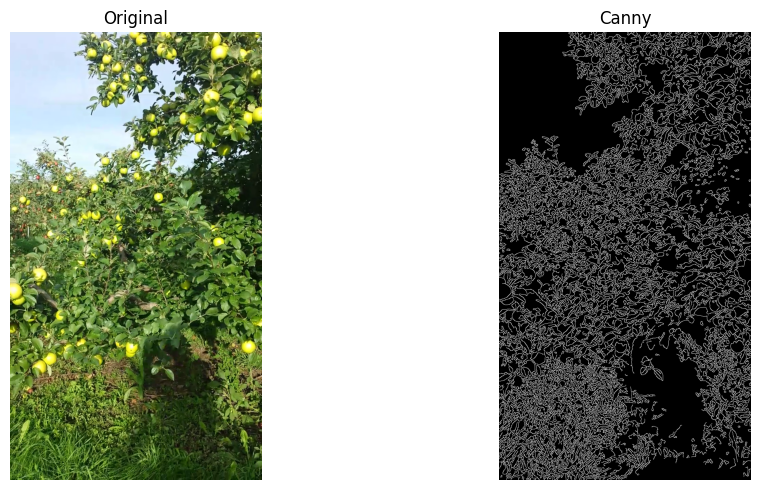

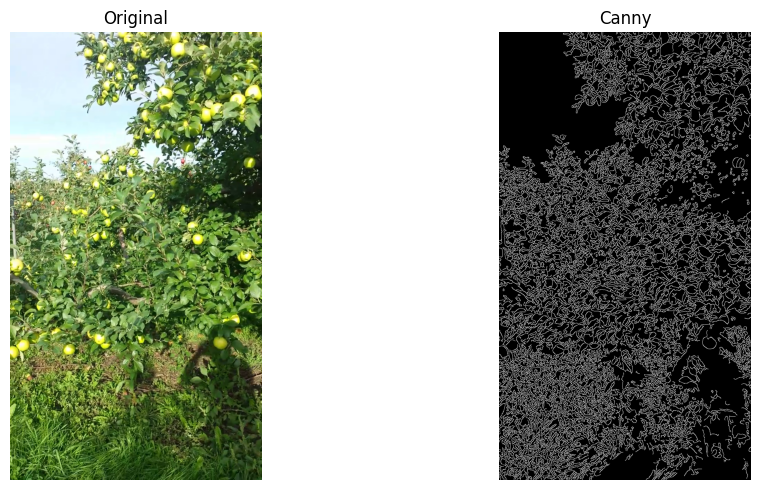

                   iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                      
b185 referencia  0.365  0.489      0.590   0.441   0.263           0.24       0.298        29.757     31.071
Hough círculos   0.047  0.089      0.047   1.000   0.000           0.00       0.000       -58.700     58.700


In [36]:
# =========================
# 3. CANNY + HOUGH DE CÍRCULOS
# =========================
def bordes_canny(img, bajo=50, alto=150, sigma=1.5):
    gris = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    gris = cv.GaussianBlur(gris, (5, 5), sigma)
    return cv.Canny(gris, bajo, alto)

def hough_circulos_manzanas(
    img,
    dp=1.2,
    min_dist=25,
    param1=100,
    param2=25,
    min_radius=8,
    max_radius=80
):
    """
    Detecta círculos mediante Hough y crea una máscara binaria.
    Se restringe después por color para evitar que cualquier círculo del follaje
    se convierta directamente en una detección de manzana.
    """
    gris = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    gris = cv.GaussianBlur(gris, (5, 5), 1.5)

    circulos = cv.HoughCircles(
        gris, cv.HOUGH_GRADIENT,
        dp=dp,
        minDist=min_dist,
        param1=param1,
        param2=param2,
        minRadius=min_radius,
        maxRadius=max_radius
    )

    mascara = np.zeros(gris.shape, dtype=np.uint8)

    if circulos is None:
        return mascara

    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    # Rango de color de partida, heredado del análisis previo.
    color = cv.inRange(hsv, (22, 50, 50), (45, 255, 255))

    for x, y, r in np.round(circulos[0]).astype(int):
        if 0 <= x < gris.shape[1] and 0 <= y < gris.shape[0]:
            region = np.zeros_like(mascara)
            cv.circle(region, (x, y), r, 255, -1)

            # Un círculo solo se conserva si una parte razonable de su interior
            # tiene el color característico de las manzanas.
            cobertura_color = np.mean(color[region > 0] > 0) if np.any(region > 0) else 0
            if cobertura_color >= 0.20:
                mascara[region > 0] = 255

    return mascara

CATALOGO["hough_circulos"] = hough_circulos_manzanas

# Canny se visualiza directamente porque es un detector de bordes, no una
# segmentación binaria final.
for nombre in ajuste[:2]:
    img, gt = cargar_par(nombre)
    edges = bordes_canny(img)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax[0].set_title("Original")
    ax[1].imshow(edges, cmap="gray")
    ax[1].set_title("Canny")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()

metodos_hough = [
    Metodo(
        "Hough círculos",
        seg=("hough_circulos", {}),
        post=[
            ("abrir_cerrar", {"k_abrir": 3, "k_cerrar": 5}),
            ("filtrar_area", {"area_min": 40})
        ]
    ),
    Metodo(
        "b185 referencia",
        preproc=[("mediana", {"k": 5})],
        seg=("umbral_b", {"lo": 185}),
        post=post_otsu
    )
]

tabla_hough = comparar(metodos_hough, ajuste)
print(resumen(tabla_hough).round(3).to_string())


### Nota sobre Hough

Hough no tiene por qué ser el método final.

Su interés aquí es comprobar si la **forma aproximadamente circular** de las manzanas aporta información que el color no consigue proporcionar.

Si detecta muchos círculos falsos o pierde muchas manzanas, se documenta como resultado negativo y se descarta.


In [37]:
# =========================
# 4. WATERSHED
# =========================
def watershed_dist(mascara, img, frac=0.7):
    """
    Separa regiones conectadas usando la transformada de distancia.
    frac controla cuánto de la distancia máxima de cada componente se usa
    para construir las semillas.
    """
    m = (mascara > 0).astype(np.uint8)

    # Distancia al fondo.
    dist = cv.distanceTransform(m, cv.DIST_L2, 5)

    # Componentes conectados de la máscara inicial.
    n, etiquetas = cv.connectedComponents(m, connectivity=8)

    semillas = np.zeros_like(m)
    for i in range(1, n):
        region = etiquetas == i
        max_dist = dist[region].max() if np.any(region) else 0
        if max_dist > 0:
            semillas[region & (dist >= frac * max_dist)] = 1

    # Si no hay semillas, devolvemos la máscara original.
    if semillas.sum() == 0:
        return m * 255

    n_sem, marcadores = cv.connectedComponents(semillas)
    marcadores = marcadores + 1

    # Fondo conocido = 1, regiones por decidir = 0.
    marcadores[m == 0] = 1
    marcadores[(m == 1) & (semillas == 0)] = 0

    # Watershed trabaja sobre una imagen de 3 canales.
    imagen_ws = img.copy()
    marcadores = cv.watershed(imagen_ws, marcadores.astype(np.int32))

    # Todo marcador de objeto >= 2 es una región separada.
    salida = (marcadores >= 2).astype(np.uint8)

    return salida * 255

CATALOGO["watershed_dist"] = watershed_dist

post_ref = [
    ("abrir_cerrar", {"k_abrir": 3, "k_cerrar": 11}),
    ("rellenar_huecos", {}),
    ("dilatar", {"k": 5}),
]

metodos_ws = [
    Metodo(
        "referencia antes de Watershed",
        preproc=[("mediana", {"k": 5})],
        seg=("umbral_b", {"lo": 185}),
        post=post_ref + [("filtrar_area", {"area_min": 100})]
    )
]

for frac in [0.5, 0.7, 0.9]:
    metodos_ws.append(
        Metodo(
            f"Watershed frac={frac}",
            preproc=[("mediana", {"k": 5})],
            seg=("umbral_b", {"lo": 185}),
            post=post_ref + [
                ("watershed_dist", {"frac": frac}),
                ("filtrar_area", {"area_min": 100})
            ]
        )
    )

tabla_ws = comparar(metodos_ws, ajuste)
print(resumen(tabla_ws).round(3).to_string())
print("\nConteo medio:")
print(tabla_ws.groupby("metodo")[["n_gt", "n_pred"]].mean().round(1).to_string())


                                 iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                                    
referencia antes de Watershed  0.391  0.513      0.507   0.560   0.326          0.312       0.350        19.857     24.286
Watershed frac=0.5             0.345  0.469      0.624   0.394   0.292          0.316       0.277        -0.329     17.157
Watershed frac=0.7             0.314  0.439      0.643   0.347   0.271          0.313       0.245        -6.914     18.943
Watershed frac=0.9             0.224  0.342      0.650   0.239   0.212          0.271       0.178       -16.971     22.971

Conteo medio:
                               n_gt  n_pred
metodo                                     
Watershed frac=0.5             59.8    59.4
Watershed frac=0.7             59.8    52.9
Watershed frac=0.9             59.8    42.8
referencia antes de Watersh

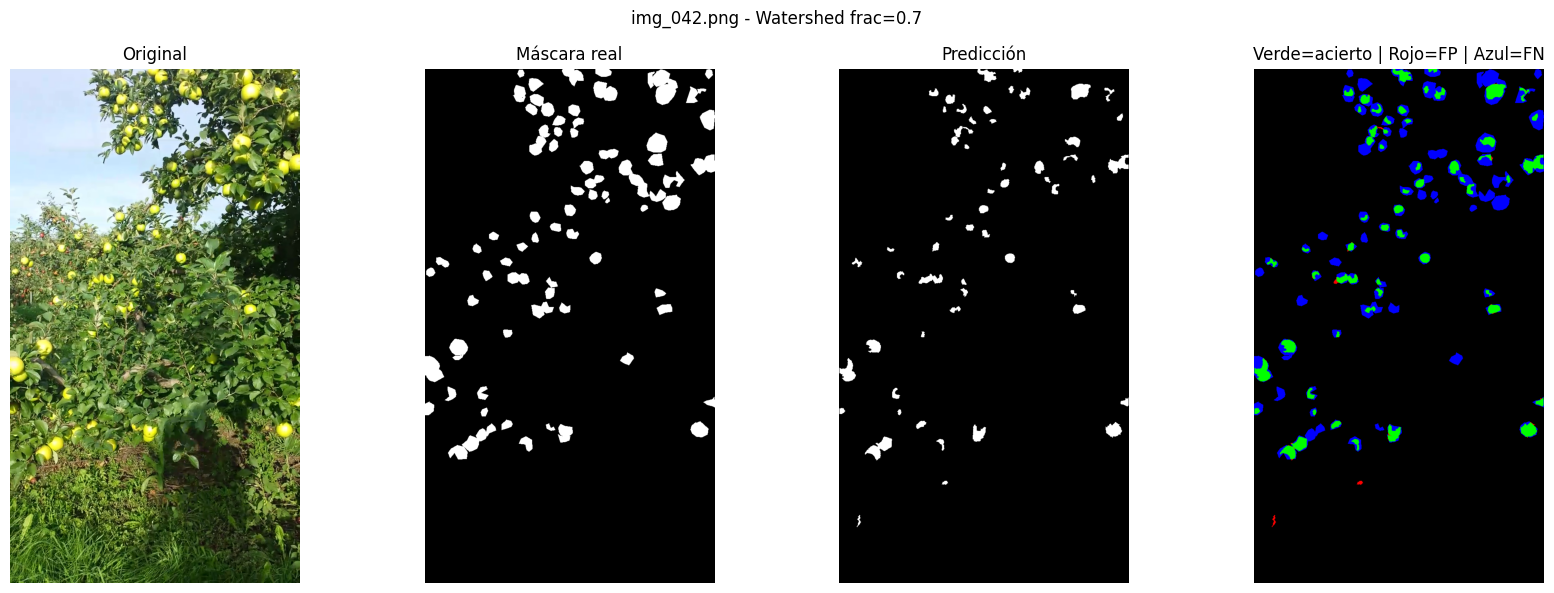

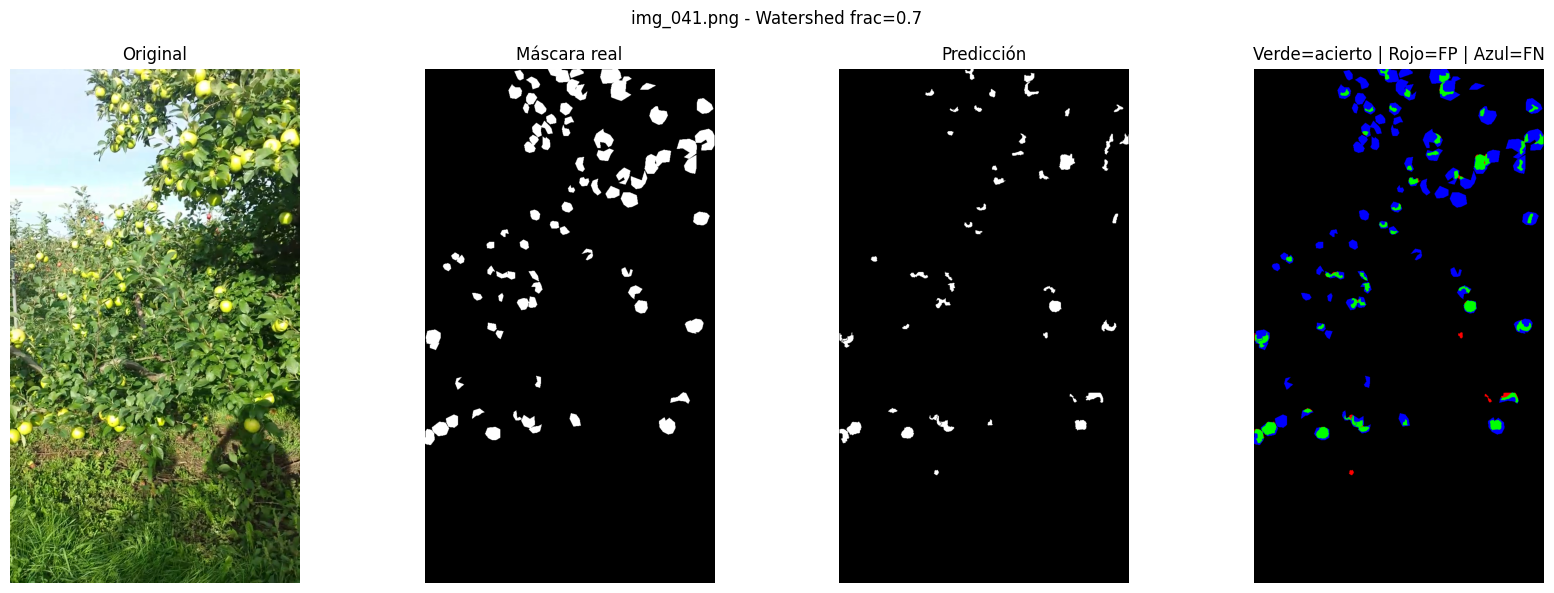

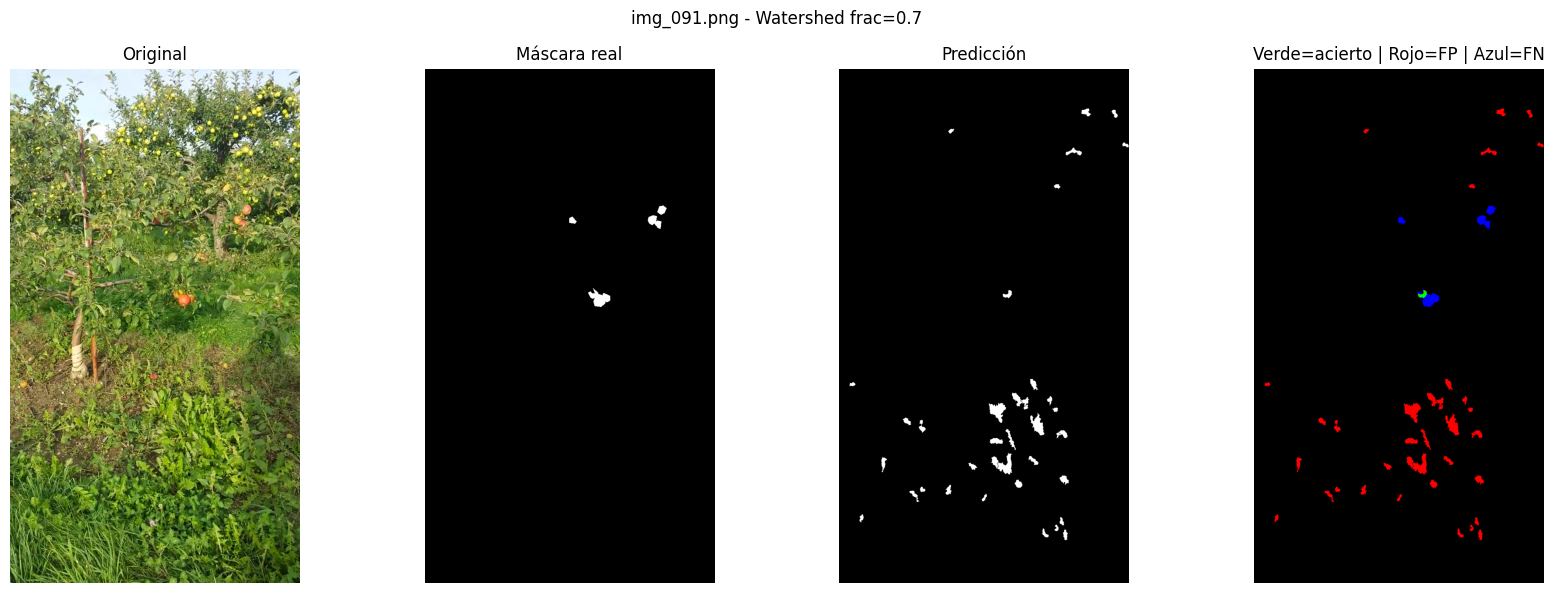

In [38]:
# Visualización de Watershed sobre ejemplos.
for nombre in ajuste[:3]:
    img, gt = cargar_par(nombre)
    metodo = metodos_ws[2]  # Watershed frac=0.7
    pred = metodo(img)
    mostrar(img, pred, gt, f"{nombre} - {metodo.nombre}")


## 5. HOG Y LBP: ANÁLISIS DE FORMA Y TEXTURA

Estas técnicas no se añaden para sustituir automáticamente la segmentación por color.

Se utilizan para comprobar si, una vez obtenidas regiones candidatas, existe información adicional de:

- **forma/bordes** mediante HOG;
- **textura local** mediante LBP.

Esto está alineado con el Tema 6, donde HOG se centra en bordes, gradientes y dirección de los bordes, mientras que LBP caracteriza patrones locales de textura.

Si las distribuciones de las características de manzana y fondo son muy parecidas, se documentará que no aportan una mejora clara.


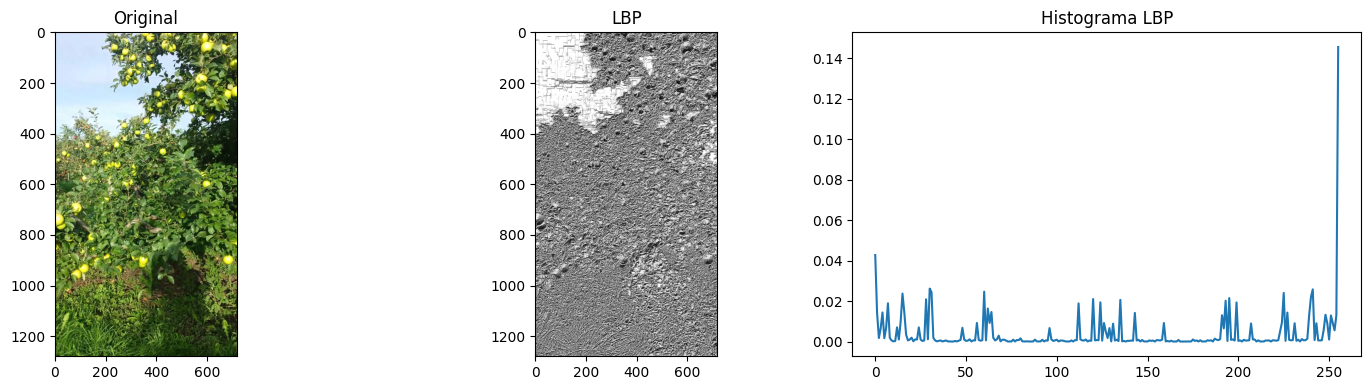

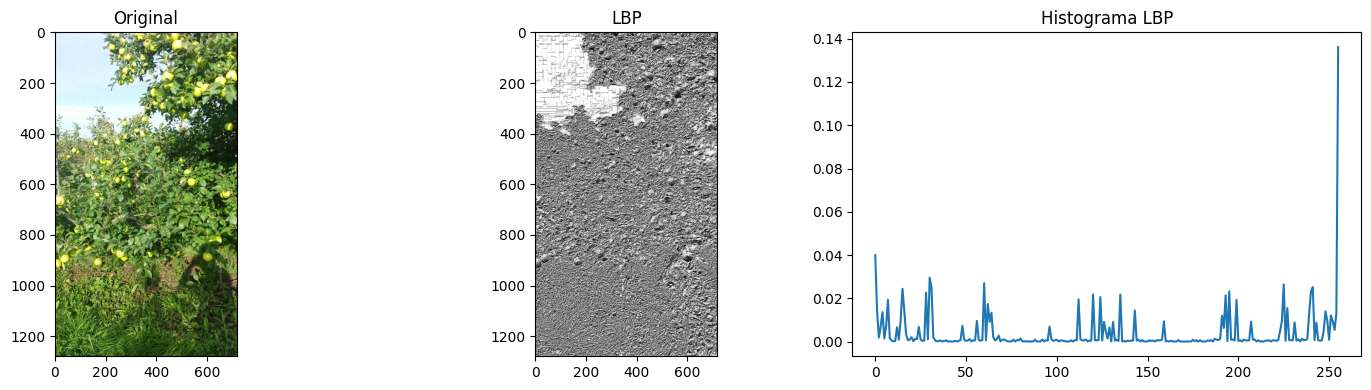

In [39]:
# =========================
# 5A. LBP
# =========================
def lbp_imagen(gris, radius=1, points=8):
    """
    LBP básico con vecinos circulares aproximados mediante cv.remap.
    Devuelve el mapa LBP y su histograma normalizado.
    """
    gris = gris.astype(np.float32)
    h, w = gris.shape
    centro = gris

    lbp = np.zeros((h, w), dtype=np.uint8)
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)

    for p in range(points):
        angulo = 2 * np.pi * p / points
        dx = radius * np.cos(angulo)
        dy = -radius * np.sin(angulo)

        vecino = cv.remap(
            gris,
            xx + dx,
            yy + dy,
            interpolation=cv.INTER_LINEAR,
            borderMode=cv.BORDER_REFLECT
        )

        lbp |= ((vecino >= centro).astype(np.uint8) << p)

    hist = np.bincount(lbp.ravel(), minlength=2 ** points).astype(np.float64)
    hist /= hist.sum() if hist.sum() else 1.0
    return lbp, hist

def caracteristicas_lbp_region(img, mascara):
    gris = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    _, hist = lbp_imagen(gris)
    return hist

# Ejemplo visual.
for nombre in ajuste[:2]:
    img, gt = cargar_par(nombre)
    gris = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    lbp, hist = lbp_imagen(gris)

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax[0].set_title("Original")
    ax[1].imshow(lbp, cmap="gray")
    ax[1].set_title("LBP")
    ax[2].plot(hist)
    ax[2].set_title("Histograma LBP")
    plt.tight_layout()
    plt.show()


In [40]:
# =========================
# 5B. HOG
# =========================
hog = cv.HOGDescriptor(
    (64, 64),   # ventana
    (16, 16),   # bloque
    (8, 8),     # stride
    (8, 8),     # celda
    9            # orientaciones
)

def hog_region(img, mascara=None, size=(64, 64)):
    gris = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    if mascara is not None:
        gris = cv.bitwise_and(gris, gris, mask=(mascara > 0).astype(np.uint8) * 255)

    gris = cv.resize(gris, size)
    descriptor = hog.compute(gris)
    return descriptor.ravel()

# Ejemplo: descriptor HOG de una imagen.
for nombre in ajuste[:2]:
    img, gt = cargar_par(nombre)
    h = hog_region(img, gt)
    print(nombre, "-> longitud descriptor HOG:", len(h))


img_042.png -> longitud descriptor HOG: 1764
img_041.png -> longitud descriptor HOG: 1764


### Decisión sobre HOG/LBP

No se debe forzar su uso en el método final.

Si HOG/LBP se emplean solo como descriptores exploratorios, basta con explicar qué información aportan y por qué se conservan o descartan.

La segmentación sigue siendo el núcleo del proyecto.


# 6. SELECCIÓN DE MÉTODOS SOLO CON EL CONJUNTO DE AJUSTE

A partir de aquí se cierra la fase de experimentación.

**Importante:** el conjunto `test` no se utiliza para elegir parámetros ni para decidir qué método gana.

Se comparan varios candidatos sobre `ajuste` y se seleccionan los mejores.
Después se evalúan esos candidatos una sola vez sobre `test`.


In [41]:
# =========================
# CANDIDATOS FINALES
# =========================
post_final = [
    ("abrir_cerrar", {"k_abrir": 3, "k_cerrar": 11}),
    ("rellenar_huecos", {}),
    ("filtrar_area", {"area_min": 100})
]

candidatos = [
    Metodo(
        "A - Lab b=185",
        preproc=[("mediana", {"k": 5})],
        seg=("umbral_b", {"lo": 185}),
        post=post_final
    ),

    Metodo(
        "B - Otsu b",
        preproc=[("mediana", {"k": 5})],
        seg=("otsu_b", {}),
        post=post_final
    ),

    Metodo(
        "C - Otsu gris",
        preproc=[("mediana", {"k": 5})],
        seg=("otsu_gris", {}),
        post=post_final
    ),

    Metodo(
        "D - GMM k=6",
        preproc=[("mediana", {"k": 5})],
        seg=("gmm_color", {"k": 6}),
        post=post_final
    ),

    Metodo(
        "E - Hough círculos",
        seg=("hough_circulos", {}),
        post=[
            ("abrir_cerrar", {"k_abrir": 3, "k_cerrar": 5}),
            ("filtrar_area", {"area_min": 40})
        ]
    ),
]

tabla_ajuste_final = comparar(candidatos, ajuste)
resumen_ajuste = resumen(tabla_ajuste_final)
print(resumen_ajuste.round(3).to_string())

mejor_dice = resumen_ajuste.index[0]
mejor_obj = resumen_ajuste.sort_values("obj_f1", ascending=False).index[0]

print("\nMejor por Dice:", mejor_dice)
print("Mejor por F1 de objeto:", mejor_obj)


                      iou   dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                         
A - Lab b=185       0.373  0.496      0.596   0.447   0.297          0.331       0.276        -4.371     18.200
D - GMM k=6         0.256  0.350      0.417   0.456   0.219          0.266       0.191         3.843     29.443
C - Otsu gris       0.072  0.132      0.074   0.775   0.022          0.023       0.030         3.557     40.814
B - Otsu b          0.062  0.115      0.062   0.985   0.019          0.040       0.014       -42.614     44.500
E - Hough círculos  0.047  0.089      0.047   1.000   0.000          0.000       0.000       -58.700     58.700

Mejor por Dice: A - Lab b=185
Mejor por F1 de objeto: A - Lab b=185


### Criterio de selección

Hay dos objetivos distintos:

- **Dice / IoU de píxel:** mide la calidad de la máscara.
- **F1 de objeto:** mide mejor la capacidad de identificar manzanas individuales.

Por eso no se debe ocultar si un método gana en píxel pero pierde en objeto.

La selección final debe justificarse según el objetivo principal del proyecto: identificar correctamente las manzanas.


In [42]:
# =========================
# 7. EVALUACIÓN FINAL EN TEST
# =========================
# Solo se evalúan aquí los candidatos que ya han sido seleccionados usando ajuste.
# No se modifican sus parámetros después de mirar test.

# Puedes cambiar estos nombres DESPUÉS de observar la tabla de ajuste.
seleccionados = [
    mejor_dice,
    mejor_obj
]

seleccionados = list(dict.fromkeys(seleccionados))
metodos_test = [m for m in candidatos if m.nombre in seleccionados]

tabla_test = comparar(metodos_test, test)
print("RESULTADOS FINALES EN TEST")
print(resumen(tabla_test).round(3).to_string())


RESULTADOS FINALES EN TEST
                 iou  dice  precision  recall  obj_f1  obj_precision  obj_recall  error_conteo  error_abs
metodo                                                                                                   
A - Lab b=185  0.298   0.4       0.47   0.376   0.229           0.26        0.21        -0.167     20.633


In [43]:
# Tabla compacta para la memoria.
tabla_final_memoria = (
    tabla_test.groupby("metodo")
    [["iou", "dice", "precision", "recall",
      "obj_precision", "obj_recall", "obj_f1",
      "n_gt", "n_pred", "error_abs"]]
    .mean()
    .round(3)
)

tabla_final_memoria


,iou,dice,precision,recall,obj_precision,obj_recall,obj_f1,n_gt,n_pred,error_abs
metodo,,,,,,,,,,
A - Lab b=185,0.298,0.4,0.47,0.376,0.26,0.21,0.229,52.767,52.6,20.633


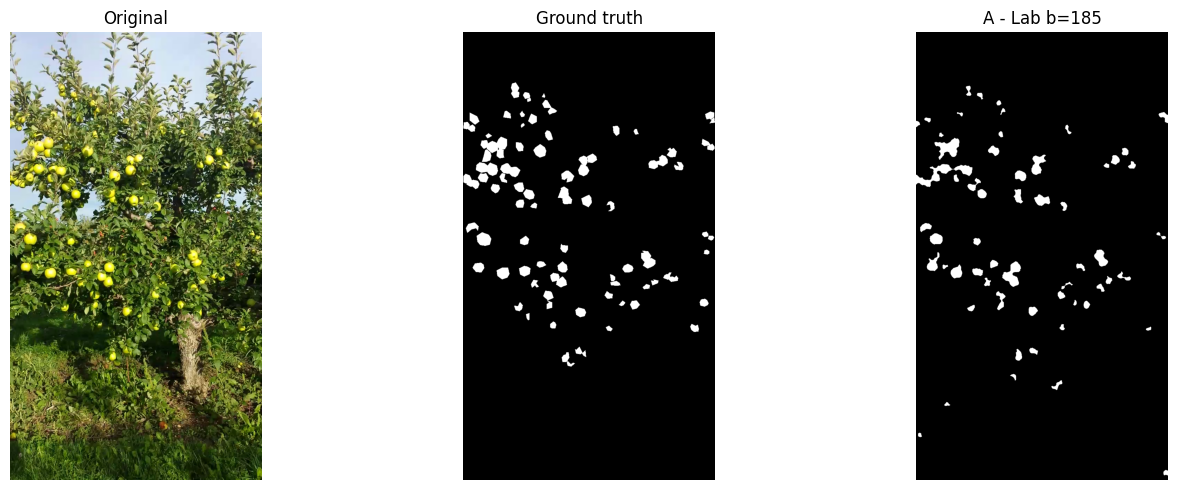

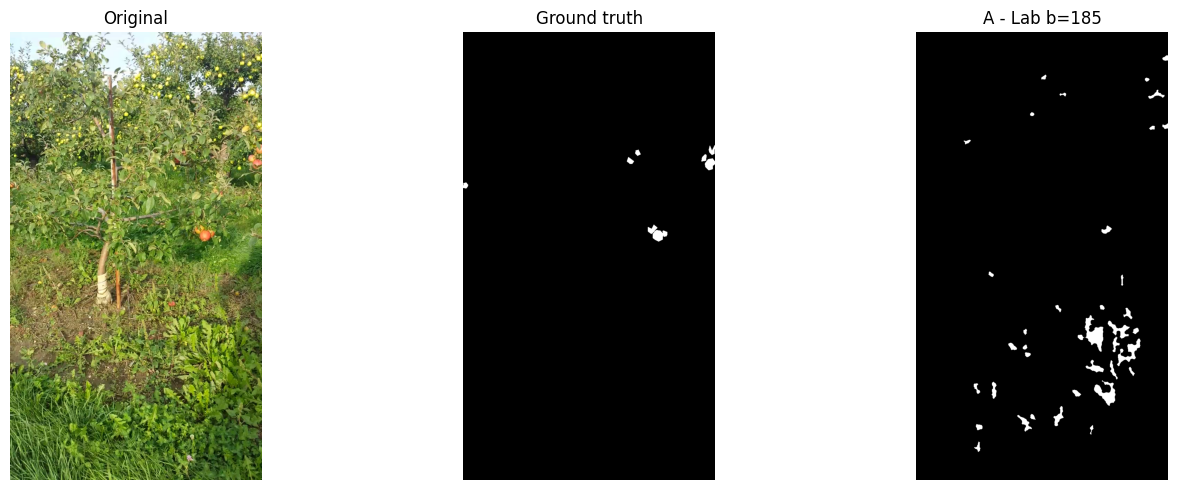

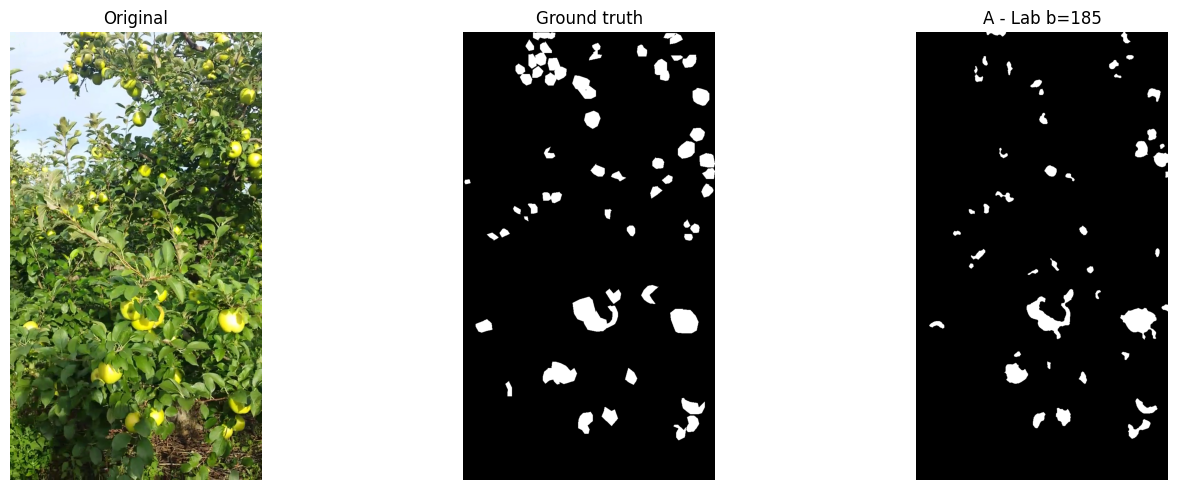

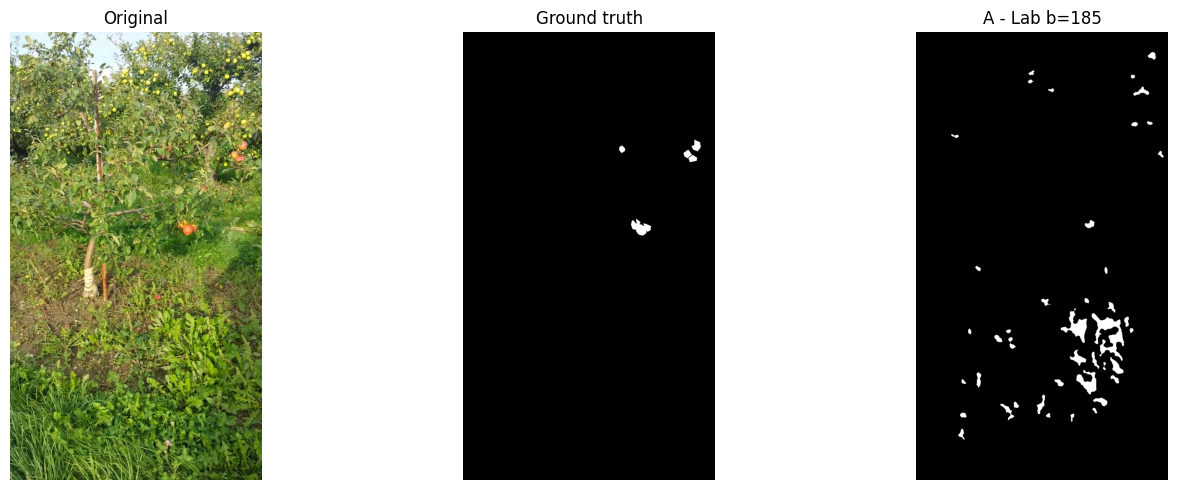

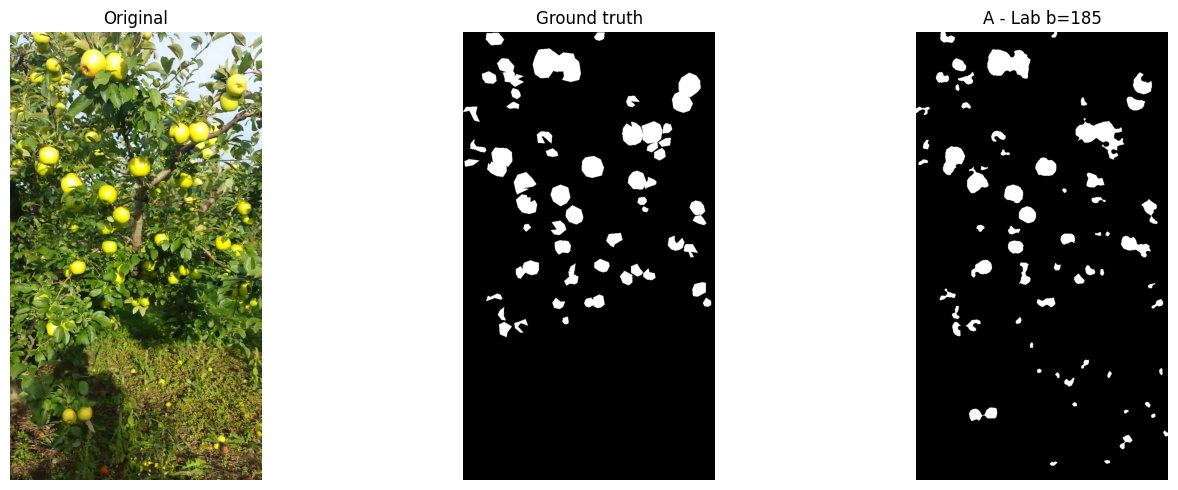

In [44]:
# =========================
# 8. VISUALIZACIÓN FINAL
# =========================
# Mostrar ejemplos del TEST, nunca usados para ajustar.
for nombre in test[:5]:
    img, gt = cargar_par(nombre)

    fig, ax = plt.subplots(1, 2 + len(metodos_test), figsize=(5 * (2 + len(metodos_test)), 5))
    ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax[0].set_title("Original")
    ax[0].axis("off")

    ax[1].imshow(gt, cmap="gray")
    ax[1].set_title("Ground truth")
    ax[1].axis("off")

    for j, metodo in enumerate(metodos_test, start=2):
        pred = metodo(img)
        ax[j].imshow(pred, cmap="gray")
        ax[j].set_title(metodo.nombre)
        ax[j].axis("off")

    plt.tight_layout()
    plt.show()


# 9. CONCLUSIONES AUTOMÁTICAS PARA LA MEMORIA

Al terminar de ejecutar el notebook, conviene registrar:

1. Qué espacio de color funcionó mejor.
2. Si Otsu mejoró frente al umbral manual.
3. Si Gaussiano o CLAHE aportaron mejora real.
4. Si Canny/Hough aportaron información útil.
5. Si Watershed redujo los errores de objetos pegados.
6. Si HOG/LBP aportaron información adicional o se descartaron.
7. Qué método fue mejor en ajuste.
8. Qué método mantuvo mejor rendimiento en test.
9. La diferencia entre métricas de píxel y métricas de objeto.
10. Ejemplos visuales de falsos positivos y falsos negativos.

No se deben seleccionar técnicas solo porque estén en el temario: se conservan las que demuestren utilidad en este problema.
